#### DSC530-T302 Data Exploration and Analysis
#### Week 11
#### Final Project
#### Kyle Gotzman

---

# Combined Cycle Power Plant: Exploratory Data Analysis

**Problem Statement:** How do conditions (temperature, pressure, humidity, exhaust vacuum) affect electrical power output in a combined cycle power plant? Can we predict power output and classify operating regimes using statistical and machine learning methods?

**Dataset:** (https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) (https://www.kaggle.com/datasets/rinichristy/combined-cycle-power-plant-data-set-uci-data)

## 1. Set Up

In [23]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    fowlkes_mallows_score, mean_squared_error, r2_score,
    classification_report, confusion_matrix, roc_curve, auc, RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Dataset Selection & Load Data

**Source:** UCI ML Repository. Data collected from a Combined Cycle Power Plant over 6 years (2006–2011) at full load.

**Variables:**
- **AT** — Ambient Temperature (°C)
- **V** — Exhaust Vacuum (cm Hg)
- **AP** — Ambient Pressure (milibar)
- **RH** — Relative Humidity (%)
- **PE** — Net hourly electrical energy output (MW) — *target variable*

In [24]:
# Load Combined Cycle Power Plant data (Excel or CSV)
try:
    df = pd.read_excel('data/CCPP/Folds5x2_pp.xlsx')
except Exception:
    df = pd.read_csv('data/ccpp.csv')

if 'AT' not in df.columns and len(df.columns) == 5:
    df.columns = ['AT', 'V', 'AP', 'RH', 'PE']
print(f"Shape: {df.shape}")
df.head()

Shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## 3. Data Cleaning and Preparation

Handle missing values, check for outliers, and prepare data for analysis.

### 3.1 Missing Values & Data Integrity

### 3.2 Outliers (Box Plots)

### 3.3 Normalization/Standardization (for ML models)

In [25]:
# Check for missing values and data types
print("Missing values:\n", df.isnull().sum())
print("\nData types:\n", df.dtypes)
print("\nSummary:\n", df.describe())

Missing values:
 AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Data types:
 AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Summary:
                 AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000


## 4. EDA — Variable Characteristics & Summary Statistics

Describe the variables and provide summary statistics. 

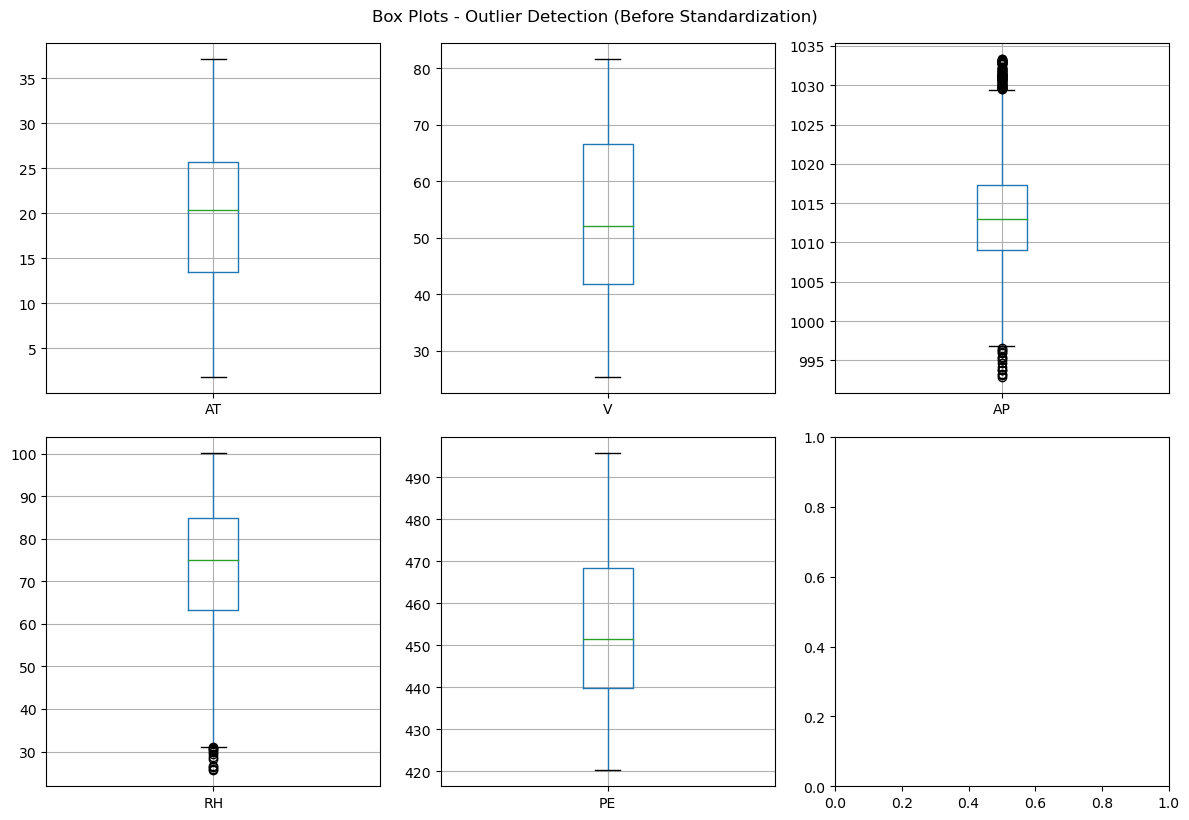

In [26]:
# Box plots to visualize outliers (BEFORE standardization)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, col in enumerate(df.columns):
    ax = axes.flat[i]
    df.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.suptitle('Box Plots - Outlier Detection (Before Standardization)', y=1.02)
plt.show()

**Box plot findings:** AP (Ambient Pressure) and RH (Relative Humidity) show visible outliers—points beyond the whiskers. AT, V, and PE do not show significant outliers.

**Outlier handling—why no trimming or removal:** We did not trim or remove outliers. The outliers in AP and RH are relatively few and not extreme. Trimming would discard valid observations and reduce sample size. Instead, we applied standardization, which scales variables to comparable ranges and reduces the influence of extreme values without removing data. Our ML models (Random Forest, K-means) are robust to outliers. Standardization prepares the data for clustering and ML.

In [27]:
# Create binary target for classification: High (1) vs Low (0) power output
df['PE_high'] = (df['PE'] >= df['PE'].median()).astype(int)
# Scale features for clustering/ML (store in X_scaled for later use)
scaler = StandardScaler()
X = df[['AT', 'V', 'AP', 'RH']]
X_scaled = scaler.fit_transform(X)
print("Standardization applied. Ready for clustering and ML models.")

Standardization applied. Ready for clustering and ML models.


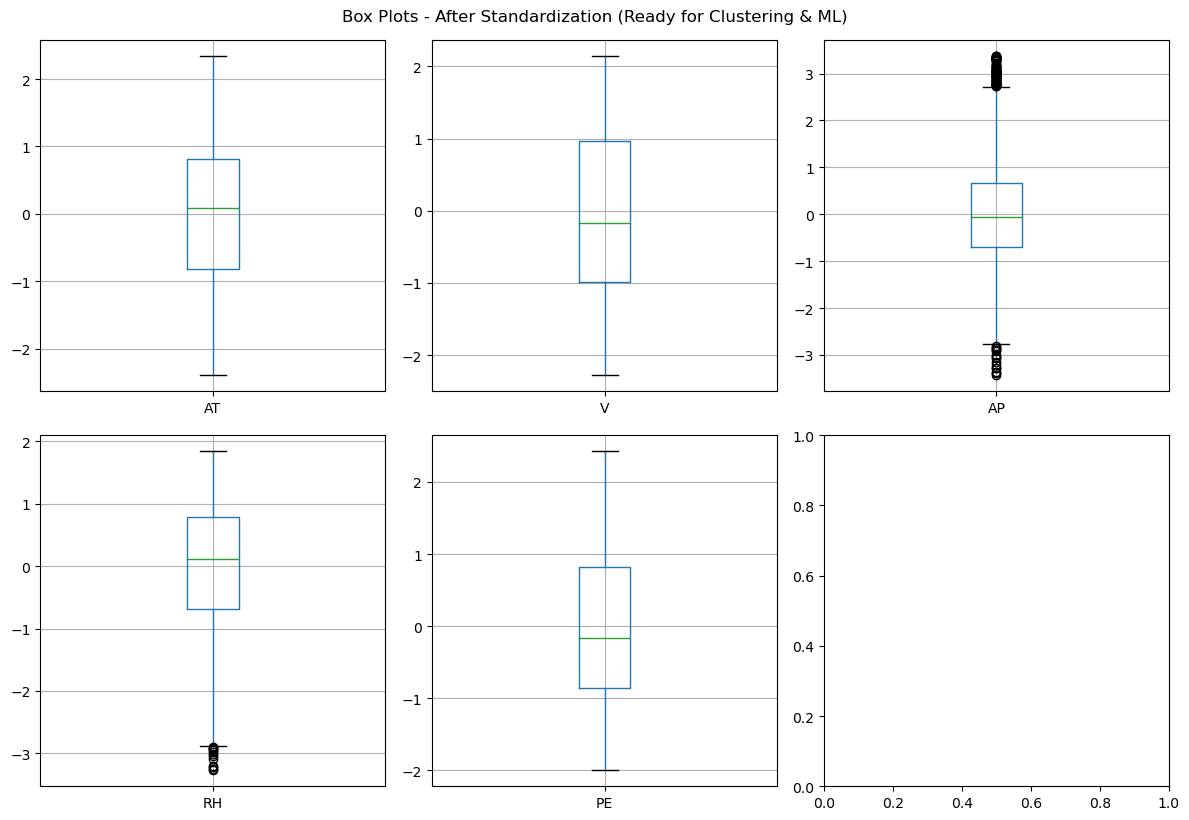

In [28]:
# Box plots AFTER standardization — same scale for all variables; ready for clustering and ML
scaler_full = StandardScaler()
df_scaled = pd.DataFrame(scaler_full.fit_transform(df[['AT','V','AP','RH','PE']]), columns=['AT','V','AP','RH','PE'])
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, col in enumerate(df_scaled.columns):
    ax = axes.flat[i]
    df_scaled.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.suptitle('Box Plots - After Standardization (Ready for Clustering & ML)', y=1.02)
plt.show()

In [29]:
# Variable characteristics: mean, median, mode, variance, skewness, kurtosis
stats_df = pd.DataFrame({
    'mean': df[['AT','V','AP','RH','PE']].mean(),
    'median': df[['AT','V','AP','RH','PE']].median(),
    'var': df[['AT','V','AP','RH','PE']].var(),
    'skewness': df[['AT','V','AP','RH','PE']].skew(),
    'kurtosis': df[['AT','V','AP','RH','PE']].kurtosis()
})
stats_df

,mean,median,var,skewness,kurtosis
AT,19.651231,20.345,55.539357,-0.136393,-1.037549
V,54.305804,52.080,161.490544,0.198521,-1.444337
AP,1013.259078,1012.940,35.269152,0.265445,0.094237
RH,73.308978,74.975,213.167848,-0.431839,-0.444526
PE,454.365009,451.550,291.282318,0.306509,-1.048521


**Summary statistics observations:**
- **Skewness:** All variables are roughly symmetric (skew < 0.5). RH has the largest negative skew (−0.43), indicating a slight left tail; AT, V, AP, and PE have mild positive or negative skew.
- **Kurtosis:** AT, V, PE, and RH have negative kurtosis, suggesting flatter distributions than the normal distribution. AP has near-zero kurtosis (0.09), closest to normal.
- **Mean vs. median:** Mean and median are close for all variables, consistent with near-symmetric distributions. RH shows the largest gap (mean 73.31 vs. median 74.98), matching its negative skew.
- **Variance:** RH and PE have the highest variance (213.2, 291.3); AP has the lowest (35.3). This supports the need for standardization before distance-based methods (e.g., clustering).

## 5. Univariate Analysis

Histograms, density plots, and distribution examination for key variables.

### 5.1 Histograms and Density Plots

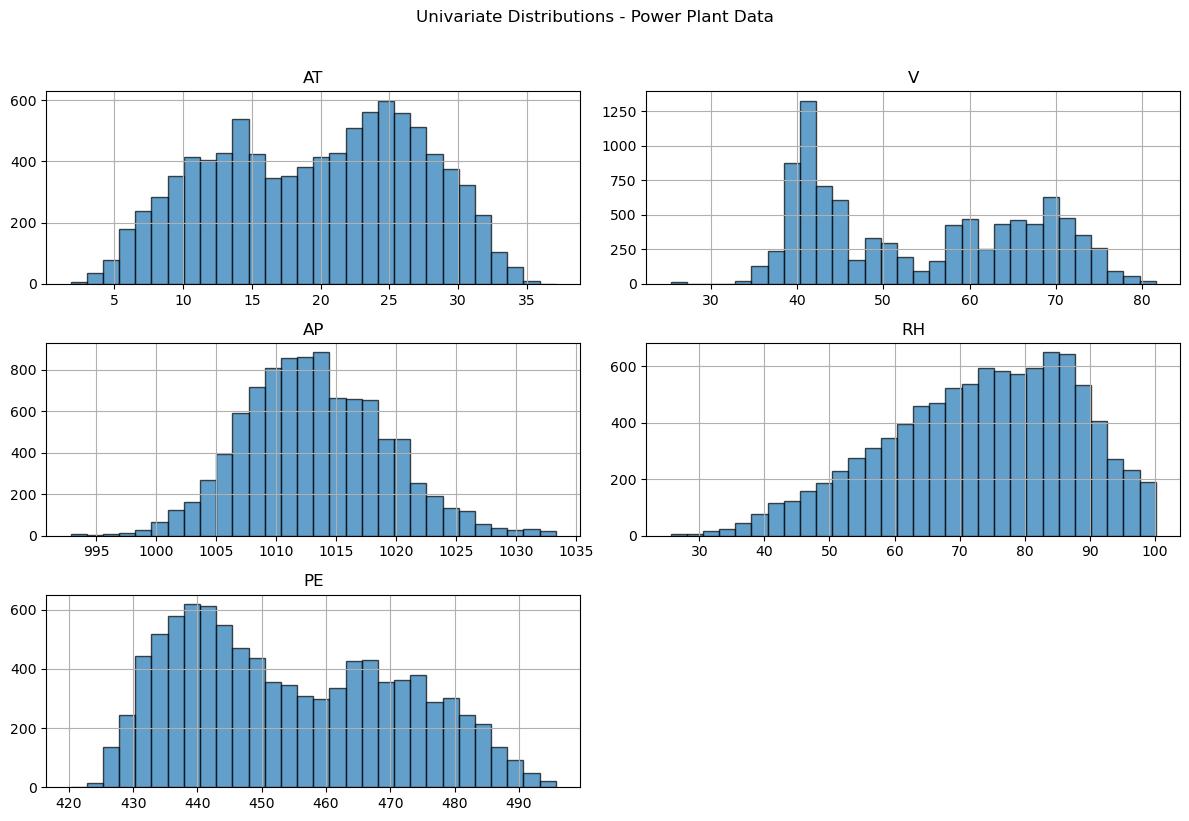

In [30]:
# Histograms for each variable
df[['AT','V','AP','RH','PE']].hist(bins=30, figsize=(12, 8), edgecolor='black', alpha=0.7)
plt.suptitle('Univariate Distributions - Power Plant Data', y=1.02)
plt.tight_layout()
plt.show()

**Univariate distribution observations:**
- **AT (Ambient Temperature):** Bimodal—two distinct peaks (~12–15°C and ~23–26°C), suggesting different operating regimes (e.g., cooler vs. warmer conditions). Explains the negative skewness and shape from the summary stats.
- **V (Exhaust Vacuum):** Multi-modal with a sharp peak around 40–42 cm Hg and smaller concentrations at 55–60 and 65–70. Slight right skew, consistent with positive skewness.
- **AP (Ambient Pressure):** Unimodal and roughly bell-shaped, closest to a normal distribution among the five variables. Aligns with near-zero kurtosis.
- **RH (Relative Humidity):** Unimodal and left-skewed, with peak around 85–88%. Longer left tail toward lower humidity values, matching the negative skewness.
- **PE (Power Output):** Bimodal with peaks around 440–445 MW and 460–465 MW, suggesting distinct high/low output regimes. The two modes may relate to the bimodal AT distribution.

## 6. Bivariate Analysis

Covariance, correlation, scatter plots, and heatmaps.

In [41]:
# Covariance matrix (measures how variables vary together; scale-dependent)
cov_matrix = df[['AT','V','AP','RH','PE']].cov()
print("Covariance matrix:")
display(cov_matrix)

Covariance matrix:


,AT,V,AP,RH,PE
AT,55.539357,79.941324,-22.463437,-59.032171,-120.593715
V,79.941324,161.490544,-31.206771,-57.922808,-188.642778
AP,-22.463437,-31.206771,35.269152,8.633874,52.546510
RH,-59.032171,-57.922808,8.633874,213.167848,97.129952
PE,-120.593715,-188.642778,52.546510,97.129952,291.282318


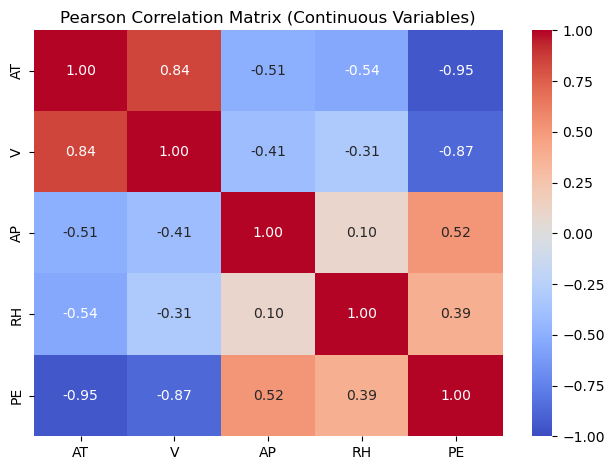

In [42]:
# Pearson correlation (for continuous variables) and heatmap
corr = df[['AT','V','AP','RH','PE']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Pearson Correlation Matrix (Continuous Variables)')
plt.tight_layout()
plt.show()

**Covariance:** The diagonal shows how much each variable varies on its own (variance). RH and PE have the largest spread. The off-diagonal values show how pairs move together—negative means one goes up when the other goes down. PE moves opposite to AT and V (negative values) and in the same direction as AP and RH (positive values). Covariance depends on scale, so we use correlation to compare strength.

**Correlation (heatmap):** Pearson correlation measures linear relationships on a −1 to 1 scale. PE is strongly tied to AT (−0.95) and V (−0.87)—as temperature or vacuum rises, power output falls. AP (0.52) and RH (0.39) have moderate positive links to PE. AT and V move together (0.84), so they carry similar information; our models can handle this.

### 6.1 Scatter Plots (Key Relationships)

**Spearman rank correlation:** For the binary target PE_high, Spearman captures rank-based relationships and is robust to non-linearity. Compare with Pearson to see if results align.

In [47]:
# Spearman rank correlation; robust to non-linearity)
# PE_high is binary (0/1); Spearman captures rank relationships
spearman_corr = df[['AT','V','AP','RH','PE','PE_high']].corr(method='spearman')
print("Spearman correlation (includes PE_high):")
display(spearman_corr[['PE_high']].sort_values('PE_high'))

Spearman correlation (includes PE_high):


,PE_high
AT,-0.834587
V,-0.801719
RH,0.329439
AP,0.484162
PE,0.866025
PE_high,1.000000


**Spearman observation:** PE_high is strongly tied to AT (−0.83) and V (−0.80)—higher temperature or vacuum tends to mean low power output. AP (0.48) and RH (0.33) have moderate positive links. PE (0.87) is strongly positive because PE_high is derived from PE. Spearman matches Pearson, so the relationships hold when we use ranks instead of raw values.

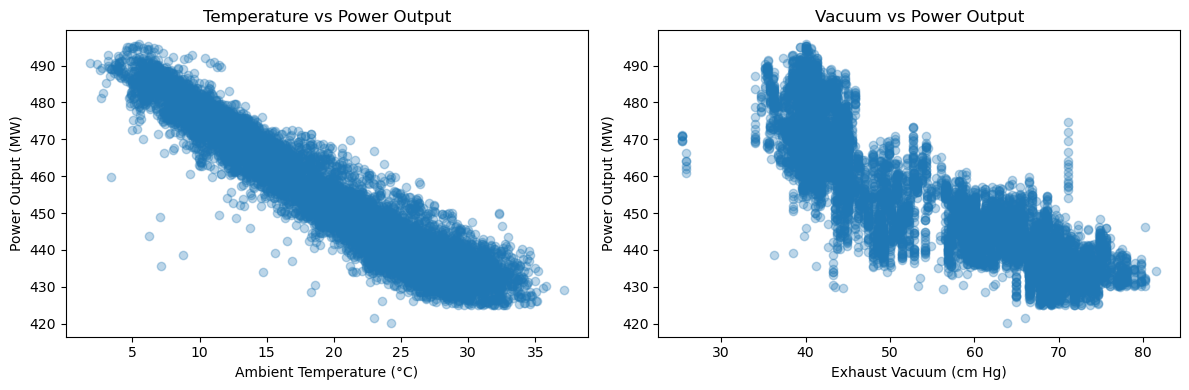

In [48]:
# Scatter: AT and V vs PE (strongest predictors)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df['AT'], df['PE'], alpha=0.3)
axes[0].set_xlabel('Ambient Temperature (°C)')
axes[0].set_ylabel('Power Output (MW)')
axes[0].set_title('Temperature vs Power Output')
axes[1].scatter(df['V'], df['PE'], alpha=0.3)
axes[1].set_xlabel('Exhaust Vacuum (cm Hg)')
axes[1].set_ylabel('Power Output (MW)')
axes[1].set_title('Vacuum vs Power Output')
plt.tight_layout()
plt.show()

**Scatter plot observations:**
- **Temperature vs Power Output:** Strong negative linear relationship—higher ambient temperature corresponds to lower power output. The tight band of points suggests AT is a reliable predictor; linear regression should capture this well.
- **Vacuum vs Power Output:** Overall negative relationship, but less linear than AT. Data forms distinct horizontal bands or clusters at different vacuum levels, suggesting a more complex or piecewise relationship. Random Forest may capture this non-linearity better than simple linear regression.

## 7. Test Statistics

Develop a hypothesis and select appropriate tests. Discuss assumptions and interpret results.

### 7.1 Hypothesis: Does temperature affect power output?

We want to know if the plant produces different amounts of power when the air is warmer versus cooler. We divide the data into high-temperature and low-temperature groups (using the median as the cutoff) and compare the average power output in each group. We use an independent samples t-test, which works well when we have two separate groups and a large enough sample size.

In [35]:
# Split by high/low AT (median split)
at_median = df['AT'].median()
high_at = df[df['AT'] >= at_median]['PE']
low_at = df[df['AT'] < at_median]['PE']
t_stat, p_val = stats.ttest_ind(high_at, low_at)
print(f"t-statistic: {t_stat:.4f}, p-value: {p_val:.6f}")
print(f"Conclusion: {'Reject H0' if p_val < 0.05 else 'Fail to reject H0'} - mean PE differs significantly between high and low temperature conditions.")

t-statistic: -148.2415, p-value: 0.000000
Conclusion: Reject H0 - mean PE differs significantly between high and low temperature conditions.


In [36]:
# F-test: Compare variances of PE across two groups
f_stat = np.var(high_at) / np.var(low_at)
df1, df2 = len(high_at) - 1, len(low_at) - 1
p_f = 2 * min(stats.f.cdf(f_stat, df1, df2), 1 - stats.f.cdf(f_stat, df1, df2))
print(f"F-statistic: {f_stat:.4f}, p-value: {p_f:.6f}")

F-statistic: 0.4376, p-value: 0.000000


In [37]:
# Welch's t-test (does not assume equal variances) — run because F-test indicated unequal variance
t_welch, p_welch = stats.ttest_ind(high_at, low_at, equal_var=False)
print(f"Welch's t-test (unequal variance): t = {t_welch:.4f}, p = {p_welch:.6f}")
print("Conclusion: Same as standard t-test — mean PE differs significantly. Welch's test is appropriate given unequal variance.")

Welch's t-test (unequal variance): t = -148.2415, p = 0.000000
Conclusion: Same as standard t-test — mean PE differs significantly. Welch's test is appropriate given unequal variance.


**Section 7 observations:**
- **t-test:** The large negative t-statistic (−148.24) and p-value ≈ 0 provide strong evidence that mean power output differs significantly between high and low temperature conditions. Higher temperature is associated with lower power output, consistent with the correlation and scatter plot findings.
- **F-test:** The two temperature groups have different spread—power output varies more in the low-temperature group than in the high-temperature group. The standard t-test assumes similar spread in both groups.
- **Welch's t-test:** Because the F-test indicated unequal variance, we ran Welch's t-test, which does not assume equal variances. The conclusion is unchanged: mean PE differs significantly between temperature groups. Welch's test is the more appropriate choice here.

## 8. Regression Analysis

Predict PE from AT, V, AP, RH. Evaluate with R squared, RMSE; interpret coefficients.

In [38]:
# Linear regression: PE ~ AT + V + AP + RH
X_reg = df[['AT', 'V', 'AP', 'RH']]
y_reg = df['PE']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)
lm = LinearRegression().fit(X_reg_train, y_reg_train)
y_pred = lm.predict(X_reg_test)
print(f"R squared: {r2_score(y_reg_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_reg_test, y_pred)):.4f}")
print("\nCoefficients:", dict(zip(X_reg.columns, lm.coef_)))
print("Intercept:", lm.intercept_)

R squared: 0.9292
RMSE: 4.5367

Coefficients: {'AT': -1.9959375173473743, 'V': -0.22893416669513514, 'AP': 0.057228121582028134, 'RH': -0.15870274758991842}
Intercept: 459.6790080068008


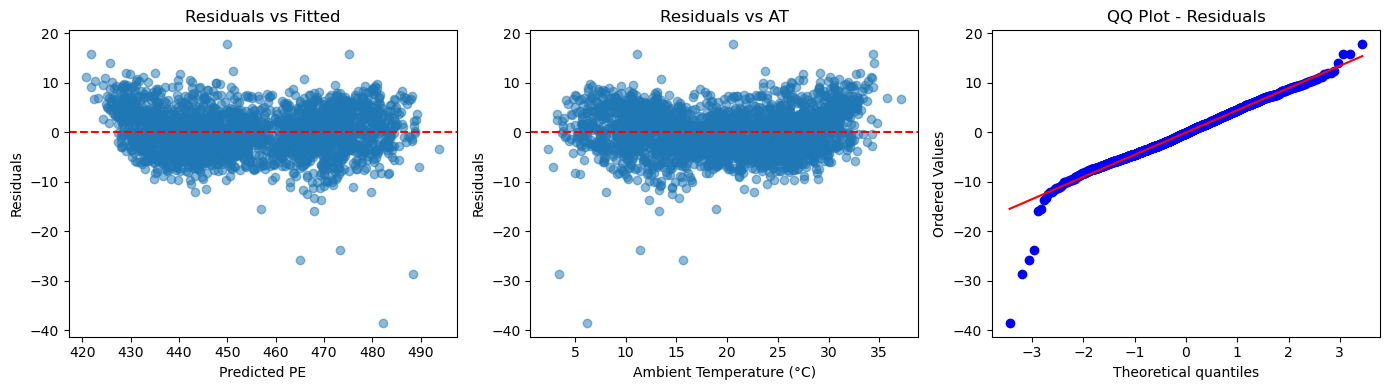

In [39]:
# Residual diagnostics: scatter (vs fitted, vs AT) and QQ plot
residuals = y_reg_test - y_pred
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(y_pred, residuals, alpha=0.5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted PE')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

axes[1].scatter(X_reg_test['AT'], residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Ambient Temperature (°C)')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residuals vs AT')

stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title('QQ Plot - Residuals')
plt.tight_layout()
plt.show()

**Residual diagnostics:** The residuals-vs-fitted plot checks for heteroscedasticity (funnel shape = unequal variance). The residuals-vs-AT plot shows whether variance changes with temperature. The QQ plot checks normality of residuals.

### 8.1 Alternative: log(PE) regression (to mitigate heteroscedasticity)

Because the F-test indicated unequal variance and residuals may vary with AT, we try log-transforming the target to stabilize variance.

log(PE) model:
R squared (on PE scale): 0.9312
RMSE (on PE scale): 4.4735


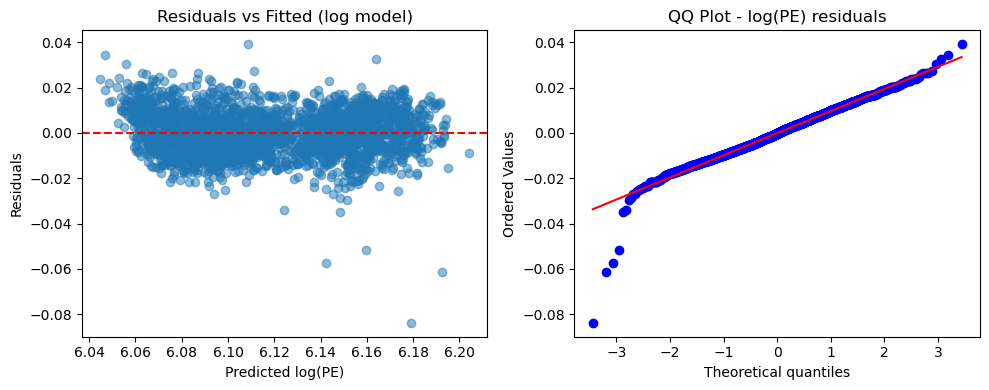

In [40]:
# log(PE) regression
y_log = np.log(y_reg)
lm_log = LinearRegression().fit(X_reg_train, np.log(y_reg_train))
y_pred_log = lm_log.predict(X_reg_test)
y_pred_pe = np.exp(y_pred_log)  # back to PE scale for comparison
residuals_log = np.log(y_reg_test) - y_pred_log

print("log(PE) model:")
print(f"R squared (on PE scale): {r2_score(y_reg_test, y_pred_pe):.4f}")
print(f"RMSE (on PE scale): {np.sqrt(mean_squared_error(y_reg_test, y_pred_pe)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_pred_log, residuals_log, alpha=0.5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted log(PE)')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (log model)')
stats.probplot(residuals_log, dist='norm', plot=axes[1])
axes[1].set_title('QQ Plot - log(PE) residuals')
plt.tight_layout()
plt.show()

**Section 8 observations:**
- **Original model:** The residual plots show unequal spread—residuals are wider at lower predicted values and narrower at higher values. The QQ plot shows heavy tails (more extreme values than a normal distribution). This matches the unequal variance we saw in the F-test.
- **log(PE) model:** The residuals spread more evenly across predicted values, and the QQ plot is closer to the line. The log transform helps stabilize the variance.
- **Prediction:** R squared and RMSE are similar for both models—the log transform does not improve prediction accuracy. Its benefit is better residual behavior, which matters for inference (e.g., confidence intervals) rather than for point predictions.

## 9. Classification Model

Classify PE_high (1=above median, 0=below) using logistic regression. Evaluate with accuracy, precision, recall, F1, ROC.

In [49]:
# Logistic regression for PE_high
X_clf = df[['AT', 'V', 'AP', 'RH']]
y_clf = df['PE_high']
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf)
logreg = LogisticRegression(max_iter=1000, random_state=42).fit(X_clf_train, y_clf_train)
preds_clf = logreg.predict(X_clf_test)
print(classification_report(y_clf_test, preds_clf, target_names=['Low PE', 'High PE']))

              precision    recall  f1-score   support

      Low PE       0.94      0.96      0.95      1196
     High PE       0.96      0.94      0.95      1196

    accuracy                           0.95      2392
   macro avg       0.95      0.95      0.95      2392
weighted avg       0.95      0.95      0.95      2392



### 9.1 ROC Curve and Confusion Matrix

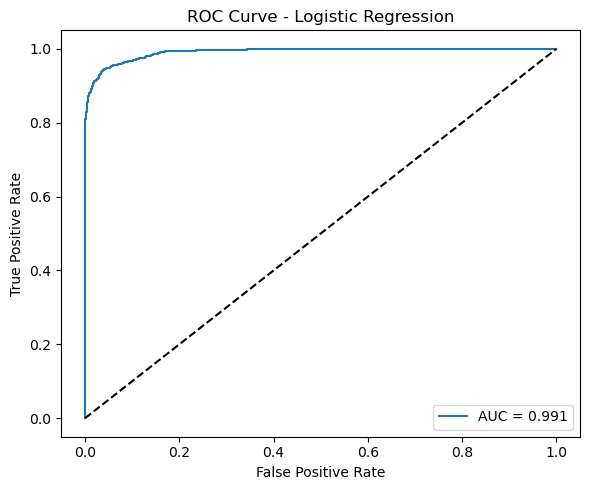

In [50]:
# ROC curve
fpr, tpr, _ = roc_curve(y_clf_test, logreg.predict_proba(X_clf_test)[:, 1])
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.tight_layout()
plt.show()

### 9.2 Confusion Matrix

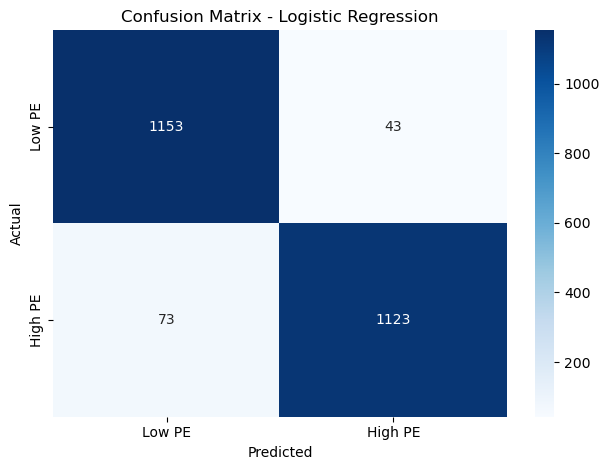

In [51]:
# Confusion matrix
cm = confusion_matrix(y_clf_test, preds_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low PE', 'High PE'], yticklabels=['Low PE', 'High PE'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

**Section 9 observations:**
- **Classification report:** Both classes (Low PE and High PE) have precision and recall around 0.94–0.96, with F1-scores of 0.95. Accuracy is 95%. The model performs well for both classes.
- **Confusion matrix:** Most predictions are correct (1153 Low PE, 1123 High PE). Errors are small: 43 low-output cases predicted as high, 73 high-output cases predicted as low.
- **ROC curve:** AUC = 0.991—the model separates high and low power output very well. The curve hugs the top-left corner, meaning high true positive rate with low false positive rate.

## 10. Clustering Analysis

K-means clustering with optional PCA for visualization.

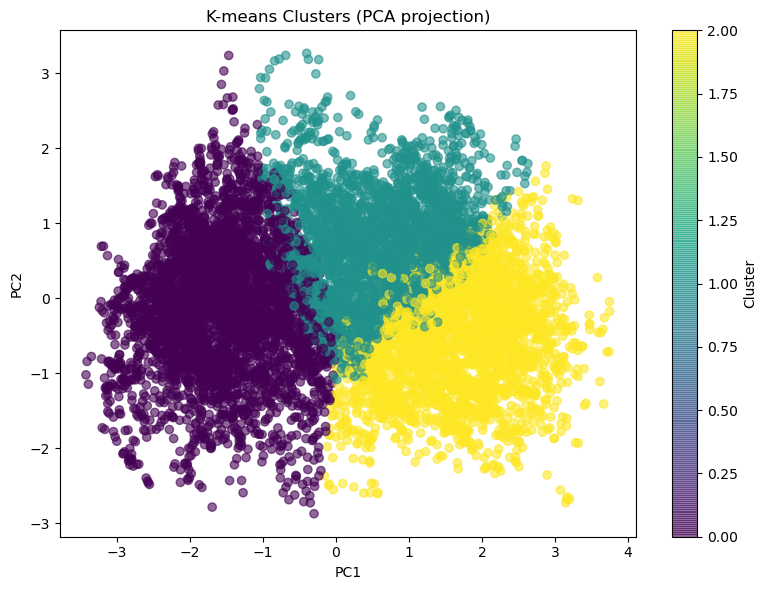

In [52]:
# K-means clustering (k=3 for low/medium/high output regimes)
kmeans = KMeans(n_clusters=3, random_state=42).fit(X_scaled)
df['cluster'] = kmeans.labels_
# PCA for 2D visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.6)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means Clusters (PCA projection)')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()

**Section 10 observation:** K-means with k=3 finds three clusters that align with low, medium, and high power output. The PCA plot shows the clusters in 2D: they are mostly separate, with some overlap in the center where conditions blend. This supports the bimodal structure we saw in the histograms—the plant operates in distinct regimes.

## 11. Advanced ML: Random Forest

Apply Random Forest for regression or classification; compare to linear models.

### 11.1 Random Forest Regression

In [53]:
# Random Forest Regression
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_reg_train, y_reg_train)
rf_pred = rf_reg.predict(X_reg_test)
print(f"Random Forest R squared: {r2_score(y_reg_test, rf_pred):.4f}")
print(f"Random Forest RMSE: {np.sqrt(mean_squared_error(y_reg_test, rf_pred)):.4f}")

Random Forest R squared: 0.9622
Random Forest RMSE: 3.3130


### 11.2 Random Forest Classification

In [22]:
# Random Forest Classification
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_clf_train, y_clf_train)
rf_clf_preds = rf_clf.predict(X_clf_test)
print(classification_report(y_clf_test, rf_clf_preds, target_names=['Low PE', 'High PE']))

              precision    recall  f1-score   support

      Low PE       0.96      0.98      0.97      1196
     High PE       0.98      0.96      0.97      1196

    accuracy                           0.97      2392
   macro avg       0.97      0.97      0.97      2392
weighted avg       0.97      0.97      0.97      2392



**Section 11 observations:**
- **Random Forest regression:** R squared = 0.96, RMSE = 3.31. This beats the linear model (R squared ≈ 0.93, RMSE ≈ 4.54). Random Forest captures non-linear patterns (e.g., the banded Vacuum–PE relationship) that linear regression misses.
- **Random Forest classification:** Accuracy 97%, precision and recall ~0.96–0.98 for both classes. Slightly better than logistic regression (95% accuracy). Both classes are predicted well, with few errors.

---
## Limitations & Assumptions

- Data from single plant; may not generalize to others.
- Linear relationships assumed for regression; non-linear effects possible.
- Classification uses median split; alternative thresholds could be explored.

---
*References: Tüfekci, P. (2014). Prediction of full load electrical power output of a base load operated combined cycle power plant using machine learning methods. International Journal of Electrical Power & Energy Systems, 60, 126-140.*